In [5]:
import re
import os
import time
import random
import warnings

import torch
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

from tqdm import tqdm
from torch.export import export
from torchvision import datasets
from torchvision.io import decode_image
from torchao.quantization.pt2e.quantize_pt2e import convert_pt2e, prepare_pt2e

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner
from executorch.backends.xnnpack.quantizer.xnnpack_quantizer import XNNPACKQuantizer, get_symmetric_quantization_config

from transformer_net import TransformerNet


random.seed(0)
warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [2]:
# NOTE: Use `download_saved_models.py` to download the pre-trained models before
# running this export script.
STYLES_MODELS = {
    "candy": "saved_models/candy.pth",
    "mosaic": "saved_models/mosaic.pth",
    "udnie": "saved_models/udnie.pth",
    "rain_princess": "saved_models/rain_princess.pth",
}

SUFFIX = "_xnnpack_int8"
EXPORT_DIR = "exports"
MODEL_PATH: dict[str, str] = {}

# NOTE: The original code does not resize the input image, since the network is
# fully convolutional and can handle arbitrary input sizes. However, for the
# exported model, we need to resize the input to a fixed size. The particular
# size of 640x640 is chosen to be large enough to preserve details while being
# small enough for efficient inference. This size was also used in the original
# export.
RESIZE_SIZE = [640, 640]


# Based on the implementation of `stylize()` function from:
# https://github.com/pytorch/examples/blob/main/fast_neural_style/neural_style/neural_style.py
def load_style_transfer_model(wts_path: str) -> torch.nn.Module:
    state_dict = torch.load(wts_path)
    for k in list(state_dict.keys()):
        if re.search(r"in\d+\.running_(mean|var)$", k):
            del state_dict[k]

    model = TransformerNet()
    model.load_state_dict(state_dict)
    model.eval()
    return model


def preprocess(img: torch.Tensor) -> torch.Tensor:
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)
    img = F.convert_image_dtype(img, torch.float)
    return img

In [3]:
print("Exporting models...")

# We use a common dataset of images for calibration of activation ranges. This
# particular dataset is simply reused from the semantic segmentation export
# script, but any dataset of images would work. We just need to make sure to
# apply the same preprocessing (resizing and normalization) to the images before
# passing them to the model for calibration.
#
# NOTE: There is some problem with getting the VOCSegmentation dataset to
# download in torchvision (https://github.com/pytorch/vision/issues/9269). You
# can download it from a mirror using the following commands:
# ```
# mkdir -p datasets/VOCSegmentation
# cd datasets/VOCSegmentation
# curl https://dataset.bj.bcebos.com/voc/VOCtrainval_11-May-2012.tar
# ```
#
calibration_dataset = datasets.VOCSegmentation(root="datasets/VOCSegmentation", year="2012", image_set="train")
calibration_size = 10
calibration_imgs = random.sample(calibration_dataset.images, k=calibration_size)

for model_name, wts_path in STYLES_MODELS.items():
    model = load_style_transfer_model(wts_path)
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    # NOTE: Quantization pipeline is based on the ExecuTorch example for xnnpack
    # backend:
    # https://docs.pytorch.org/executorch/1.1/backends/xnnpack/xnnpack-quantization.html

    # Prepare quantizer
    # -----------------
    quantizer = XNNPACKQuantizer()
    quantizer.set_global(get_symmetric_quantization_config(is_per_channel=True))

    # Prepare model for PTQ
    # ---------------------
    training_ep = export(model, inputs).module()
    prepared_model = prepare_pt2e(training_ep, quantizer)

    # Calibrate activation ranges
    # ---------------------------
    for img in tqdm(calibration_imgs, desc="Calibrating"):
        img = decode_image(img).unsqueeze(0)
        img = preprocess(img)
        prepared_model(img)

    # Export quantized model
    # ----------------------
    quantized_model = convert_pt2e(prepared_model)

    program = to_edge_transform_and_lower(export(quantized_model, inputs), partitioner=[XnnpackPartitioner()])
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/style_transfer_{model_name}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[model_name] = path
        f.write(program.buffer)

    print(f"Exported {path}\n")

Exporting models...


Calibrating: 100%|██████████| 10/10 [00:31<00:00,  3.18s/it]


Exported exports/style_transfer_candy_xnnpack_int8.pte



Calibrating: 100%|██████████| 10/10 [00:29<00:00,  2.91s/it]


Exported exports/style_transfer_mosaic_xnnpack_int8.pte



Calibrating: 100%|██████████| 10/10 [00:28<00:00,  2.84s/it]


Exported exports/style_transfer_udnie_xnnpack_int8.pte



Calibrating: 100%|██████████| 10/10 [00:32<00:00,  3.26s/it]


Exported exports/style_transfer_rain_princess_xnnpack_int8.pte



Visual inspection of exported models...


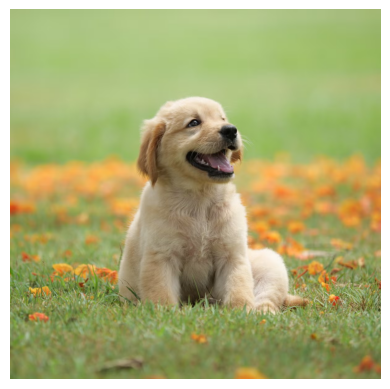

[program.cpp:154] InternalConsistency verification requested but not available
[cpuinfo_utils.cpp:71] Reading file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:87] Failed to open midr file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:167] Number of efficient cores 4


exports/style_transfer_candy_xnnpack_int8.pte
Inference time: 1.185s
Model size: 1.73 MB



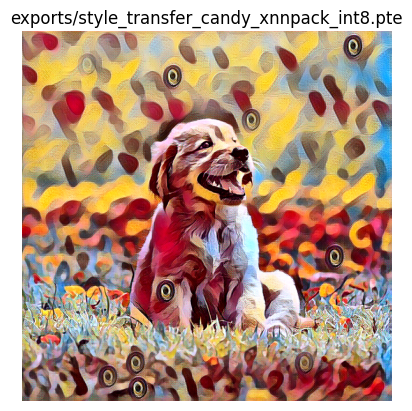

[program.cpp:154] InternalConsistency verification requested but not available


exports/style_transfer_mosaic_xnnpack_int8.pte
Inference time: 0.999s
Model size: 1.73 MB



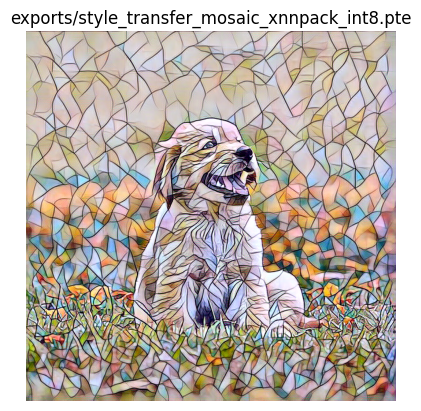

[program.cpp:154] InternalConsistency verification requested but not available


exports/style_transfer_udnie_xnnpack_int8.pte
Inference time: 0.909s
Model size: 1.73 MB



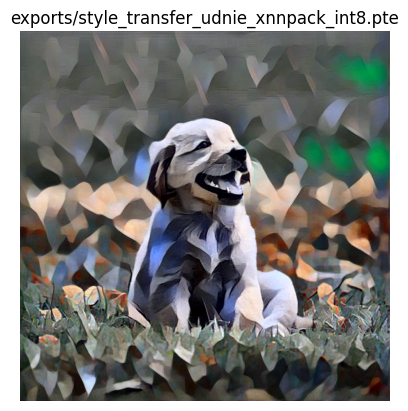

[program.cpp:154] InternalConsistency verification requested but not available


exports/style_transfer_rain_princess_xnnpack_int8.pte
Inference time: 0.845s
Model size: 1.73 MB



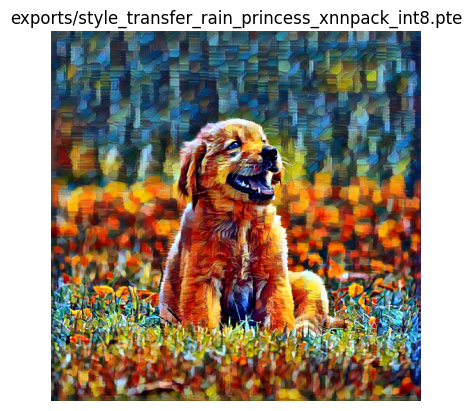

In [4]:
print("Visual inspection of exported models...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

for model_name in STYLES_MODELS:
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = preprocess(img)

    path = MODEL_PATH[model_name]
    runtime = Runtime.get()
    program = runtime.load_program(path)

    t = time.perf_counter()
    output, *_ = program.load_method("forward").execute([img])  # type: ignore
    t = time.perf_counter() - t

    print(f"{path}\n" f"Inference time: {t:.3f}s\n" f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f} MB\n")

    plt.imshow(F.to_pil_image(output[0]))
    plt.title(path)
    plt.axis("off")
    plt.show()